<a href="https://colab.research.google.com/github/philipkling/AH2179_course_labs/blob/main/Project_AH2179_TovaBurvall_PhilipKling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

# 0. Mounting Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
BUS_FOLDER = "/content/drive/MyDrive/Bus_data_2024"
WEATHER_FILE = '/content/drive/MyDrive/Project_AH2179/Data/weatherdata.xlsx'

# 1. Data preprocessing

## 1.1. Inspect the bus data

In [4]:
bus_files = sorted(glob.glob(
    os.path.join(BUS_FOLDER, "*.csv.gz")
))

sample_file = bus_files[0]

sample = pd.read_csv(
    sample_file,
    compression="gzip",
    nrows=5
)

print(sample.shape)
print(sample.columns.tolist())
display(sample.head())
print(sample.info())

(5, 5)
['date', 'route_id', 'TransportMode', 'scheduled_arrival_time_sfm', 'observed_arrival_delay']


,date,route_id,TransportMode,scheduled_arrival_time_sfm,observed_arrival_delay
0,20240101,9011001000100000,BUS,420,-60.0
1,20240101,9011001000100000,BUS,460,80.0
2,20240101,9011001000100000,BUS,494,84.0
3,20240101,9011001000100000,BUS,600,60.0
4,20240101,9011001000100000,BUS,662,49.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 5 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   date                        5 non-null      int64  
 1   route_id                    5 non-null      int64  
 2   TransportMode               5 non-null      object 
 3   scheduled_arrival_time_sfm  5 non-null      int64  
 4   observed_arrival_delay      5 non-null      float64
dtypes: float64(1), int64(3), object(1)
memory usage: 332.0+ bytes
None


## 1.2. Import and aggregate bus data

In [5]:
DATE_COL = "date"
TIME_COL = "scheduled_arrival_time_sfm"
DELAY_COL = "observed_arrival_delay"

In [6]:
hourly_parts = []

usecols = [
    DATE_COL,
    TIME_COL,
    DELAY_COL
]

for i, file_path in enumerate(bus_files):
  print(
      f"Processing {i+1}/{len(bus_files)}: "
      f"{os.path.basename(file_path)}"
  )

  chunks = []

  for chunk in pd.read_csv(
      file_path,
      compression = "gzip",
      usecols = usecols,
      chunksize = 250_000
  ):

    # Date - corrected with explicit format
    chunk[DATE_COL] = pd.to_datetime(
        chunk[DATE_COL],
        format = "%Y%m%d",
        errors = "coerce"
    )

    # Delay
    chunk[DELAY_COL] = pd.to_numeric(
        chunk[DELAY_COL],
        errors = "coerce"
    )

    # Scheduled arrival time
    chunk[TIME_COL] = pd.to_numeric(
        chunk[TIME_COL],
        errors = "coerce"
    )

    chunk = chunk.dropna(
        subset = [
            DATE_COL,
            TIME_COL,
            DELAY_COL
        ]
    )

    chunk["hour"] = (
        chunk[TIME_COL] // 3600
    ).astype(int)

    chunk = chunk[
        chunk["hour"].between(0, 23)
    ]

    grouped = (
        chunk.assign(
            delay_sum = chunk[DELAY_COL],
            delayed_count = (
                chunk[DELAY_COL] > 0
            ).astype(int),
            observation_count = 1
        ).groupby(
            [DATE_COL, "hour"]
        ).agg(
            delay_sum = ("delay_sum", "sum"),
            delayed_count = ("delayed_count", "sum"),
            observation_count = ("observation_count", "sum")
        ).reset_index()
    )

    chunks.append(grouped)

  monthly = pd.concat(
      chunks,
      ignore_index = True
  )

  monthly = (
      monthly.groupby(
          [DATE_COL, "hour"]
      ).agg(
          delay_sum = ("delay_sum", "sum"),
          delayed_count = ("delayed_count", "sum"),
          observation_count = ("observation_count", "sum")
      ).reset_index()
  )

  hourly_parts.append(monthly)

Processing 1/12: bus_202401.csv.gz
Processing 2/12: bus_202402.csv.gz
Processing 3/12: bus_202403.csv.gz
Processing 4/12: bus_202404.csv.gz
Processing 5/12: bus_202405.csv.gz
Processing 6/12: bus_202406.csv.gz
Processing 7/12: bus_202407.csv.gz
Processing 8/12: bus_202408.csv.gz
Processing 9/12: bus_202409.csv.gz
Processing 10/12: bus_202410.csv.gz
Processing 11/12: bus_202411.csv.gz
Processing 12/12: bus_202412.csv.gz


In [7]:
bus_hourly = pd.concat(
    hourly_parts,
    ignore_index=True
)

bus_hourly = (
    bus_hourly
    .groupby(
        [DATE_COL, "hour"]
    )
    .agg(
        delay_sum=("delay_sum", "sum"),
        delayed_count=("delayed_count", "sum"),
        observation_count=(
            "observation_count",
            "sum"
        )
    )
    .reset_index()
)

bus_hourly["average_delay"] = (
    bus_hourly["delay_sum"]
    / bus_hourly["observation_count"]
)

bus_hourly["percent_delayed"] = (
    bus_hourly["delayed_count"]
    / bus_hourly["observation_count"]
    * 100
)

bus_hourly = bus_hourly.sort_values(
    [DATE_COL, "hour"]
)

bus_hourly.head()

,date,hour,delay_sum,delayed_count,observation_count,average_delay,percent_delayed
0,2024-01-01,0,1753470.0,6156,7068,248.085739,87.096774
1,2024-01-01,1,2571267.0,6202,6722,382.515174,92.264207
2,2024-01-01,2,3159680.0,5131,5441,580.716780,94.302518
3,2024-01-01,3,2830381.0,4276,4423,639.923355,96.676464
4,2024-01-01,4,2214360.0,3644,3802,582.419779,95.844292


In [8]:
print("Rows:", len(bus_hourly))
display(bus_hourly.describe())

Rows: 8730


,date,hour,delay_sum,delayed_count,observation_count,average_delay,percent_delayed
count,8730,8730.000000,8.730000e+03,8730.000000,8730.000000,8730.000000,8730.000000
mean,2024-07-01 22:06:50.721649408,11.519931,1.840517e+06,14299.852005,19063.613173,93.854951,75.097527
min,2024-01-01 00:00:00,0.000000,-9.638700e+05,0.000000,1.000000,-236.244006,0.000000
25%,2024-04-02 00:00:00,6.000000,6.754620e+05,8184.000000,11466.000000,68.619062,72.007775
50%,2024-07-02 00:00:00,12.000000,1.536135e+06,14117.500000,18607.500000,86.374297,75.169420
75%,2024-10-01 00:00:00,18.000000,2.428124e+06,19886.750000,26657.250000,110.736863,78.561231
max,2024-12-31 00:00:00,23.000000,1.795384e+07,38870.000000,44331.000000,3562.000000,100.000000
std,NaN,6.924408,1.579174e+06,8361.158284,11031.550214,62.370393,5.767735


## 1.3. Import and prepare weather data

In [9]:
weather_raw = pd.read_excel(
    WEATHER_FILE
)

print(weather_raw.shape)
print(weather_raw.columns.tolist())

display(weather_raw.head())

(8782, 5)
['Tidpunkt', 'Byvind (m/s)', 'Nederbörd (mm)', 'Temperatur (°C)', 'Vindhastighet (m/s)']


,Tidpunkt,Byvind (m/s),Nederbörd (mm),Temperatur (°C),Vindhastighet (m/s)
0,2024-01-01T01:00:00+01:00,6.4,0.0,-2.4,3.8
1,2024-01-01T02:00:00+01:00,7.1,0.0,-2.4,4.1
2,2024-01-01T03:00:00+01:00,7.4,0.0,-2.2,4.2
3,2024-01-01T04:00:00+01:00,8.9,0.0,-1.9,3.8
4,2024-01-01T05:00:00+01:00,11.6,0.0,-1.8,6.4


In [10]:
weather_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8782 entries, 0 to 8781
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Tidpunkt             8782 non-null   object 
 1   Byvind (m/s)         8782 non-null   float64
 2   Nederbörd (mm)       8779 non-null   float64
 3   Temperatur (°C)      8780 non-null   float64
 4   Vindhastighet (m/s)  8782 non-null   float64
dtypes: float64(4), object(1)
memory usage: 343.2+ KB


In [11]:
weather = weather_raw.copy()

weather["Tidpunkt"] = pd.to_datetime(
    weather["Tidpunkt"],
    utc = True,
    errors = "coerce"
)

weather = weather.dropna(
    subset = ["Tidpunkt"]
)

weather["date"] = (
    weather["Tidpunkt"].dt.tz_convert("Europe/Stockholm").dt.normalize()
)

weather["hour"] = (
    weather["Tidpunkt"].dt.tz_convert("Europe/Stockholm").dt.hour
)

weather = weather.rename(
    columns = {
        "Temperatur (°C)": "temperature",
        "Nederbörd (mm)": "precipitation",
        "Vindhastighet (m/s)": "wind_speed",
        "Byvind (m/s)": "wind_gust"
    }
)

weather = weather[
    [
        "date",
        "hour",
        "temperature",
        "precipitation",
        "wind_speed",
        "wind_gust"
    ]
]

weather["date"] = weather["date"].dt.tz_localize(None)

display(weather.head())

,date,hour,temperature,precipitation,wind_speed,wind_gust
0,2024-01-01,1,-2.4,0.0,3.8,6.4
1,2024-01-01,2,-2.4,0.0,4.1,7.1
2,2024-01-01,3,-2.2,0.0,4.2,7.4
3,2024-01-01,4,-1.9,0.0,3.8,8.9
4,2024-01-01,5,-1.8,0.0,6.4,11.6


In [12]:
weather.isna().sum()

,0
date,0
hour,0
temperature,2
precipitation,3
wind_speed,0
wind_gust,0


## 1.4. Merge bus and weather data

In [13]:
bus_hourly["date"] = pd.to_datetime(
    bus_hourly[DATE_COL]
).dt.normalize()


In [14]:
data = pd.merge(
    bus_hourly,
    weather,
    on = ["date", "hour"],
    how = "inner"
)

data = data.sort_values(
    ["date", "hour"]
).reset_index(drop = True)

display(data.head())

,date,hour,delay_sum,delayed_count,observation_count,average_delay,percent_delayed,temperature,precipitation,wind_speed,wind_gust
0,2024-01-01,1,2571267.0,6202,6722,382.515174,92.264207,-2.4,0.0,3.8,6.4
1,2024-01-01,2,3159680.0,5131,5441,580.716780,94.302518,-2.4,0.0,4.1,7.1
2,2024-01-01,3,2830381.0,4276,4423,639.923355,96.676464,-2.2,0.0,4.2,7.4
3,2024-01-01,4,2214360.0,3644,3802,582.419779,95.844292,-1.9,0.0,3.8,8.9
4,2024-01-01,5,1374731.0,4377,4937,278.454730,88.657079,-1.8,0.0,6.4,11.6


# 2. Feature engineering

## 2.1. Create time features


In [15]:
data["weekday"] = (
    data["date"].dt.dayofweek
)

data["month"] = (
    data["date"].dt.month
)

data["is_weekend"] = (
    data["weekday"] >= 5
).astype(int)

data["is_rush_hour"] = (
    data["hour"].isin(
        [6, 7, 8, 9, 15, 16, 17, 18]
    )
).astype(int)

In [16]:
data["hour_sin"] = np.sin(
    2 * np.pi * data["hour"] / 24
)

data["hour_cos"] = np.cos(
    2 * np.pi * data["hour"] / 24
)

data["weekday_sin"] = np.sin(
    2 * np.pi * data["weekday"] / 7
)

data["weekday_cos"] = np.cos(
    2 * np.pi * data["weekday"] / 7
 )

## 2.2. Create lagged weather features



In [17]:
data = data.sort_values(
    ["date", "hour"]
).reset_index(drop = True)

weather_features = [
    "temperature",
    "precipitation",
    "wind_speed",
    "wind_gust"
]

for col in weather_features:
  data[f"{col}_lag1"] = (
      data[col].shift(1)
  )

  data[f"{col}_lag2"] = (
      data[col].shift(2)
  )

data["precipitation_3h"] = (
    data["precipitation"].rolling(3).sum()
)

display(data.head(10))

,date,hour,delay_sum,delayed_count,observation_count,average_delay,percent_delayed,temperature,precipitation,wind_speed,wind_gust,weekday,month,is_weekend,is_rush_hour,hour_sin,hour_cos,weekday_sin,weekday_cos,temperature_lag1,temperature_lag2,precipitation_lag1,precipitation_lag2,wind_speed_lag1,wind_speed_lag2,wind_gust_lag1,wind_gust_lag2,precipitation_3h
0,2024-01-01,1,2571267.0,6202,6722,382.515174,92.264207,-2.4,0.0,3.8,6.4,0,1,0,0,0.258819,9.659258e-01,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-01-01,2,3159680.0,5131,5441,580.716780,94.302518,-2.4,0.0,4.1,7.1,0,1,0,0,0.500000,8.660254e-01,0.0,1.0,-2.4,NaN,0.0,NaN,3.8,NaN,6.4,NaN,NaN
2,2024-01-01,3,2830381.0,4276,4423,639.923355,96.676464,-2.2,0.0,4.2,7.4,0,1,0,0,0.707107,7.071068e-01,0.0,1.0,-2.4,-2.4,0.0,0.0,4.1,3.8,7.1,6.4,0.0
3,2024-01-01,4,2214360.0,3644,3802,582.419779,95.844292,-1.9,0.0,3.8,8.9,0,1,0,0,0.866025,5.000000e-01,0.0,1.0,-2.2,-2.4,0.0,0.0,4.2,4.1,7.4,7.1,0.0
4,2024-01-01,5,1374731.0,4377,4937,278.454730,88.657079,-1.8,0.0,6.4,11.6,0,1,0,0,0.965926,2.588190e-01,0.0,1.0,-1.9,-2.2,0.0,0.0,3.8,4.2,8.9,7.4,0.0
5,2024-01-01,6,1191806.0,8339,9685,123.056892,86.102220,-2.3,0.0,4.3,7.6,0,1,0,1,1.000000,6.123234e-17,0.0,1.0,-1.8,-1.9,0.0,0.0,6.4,3.8,11.6,8.9,0.0
6,2024-01-01,7,1281761.0,10296,12505,102.499880,82.335066,-2.3,0.0,4.3,8.2,0,1,0,1,0.965926,-2.588190e-01,0.0,1.0,-2.3,-1.8,0.0,0.0,4.3,6.4,7.6,11.6,0.0
7,2024-01-01,8,1009990.0,10660,13946,72.421483,76.437688,-2.1,0.0,4.9,8.9,0,1,0,1,0.866025,-5.000000e-01,0.0,1.0,-2.3,-2.3,0.0,0.0,4.3,4.3,8.2,7.6,0.0
8,2024-01-01,9,993076.0,11906,16774,59.203291,70.978896,-2.1,0.0,4.9,8.9,0,1,0,1,0.707107,-7.071068e-01,0.0,1.0,-2.1,-2.3,0.0,0.0,4.9,4.3,8.9,8.2,0.0
9,2024-01-01,10,882048.0,12726,19051,46.299302,66.799643,-2.1,0.0,6.1,10.2,0,1,0,0,0.500000,-8.660254e-01,0.0,1.0,-2.1,-2.1,0.0,0.0,4.9,4.9,8.9,8.9,0.0


## 2.3. Descriptive analysis

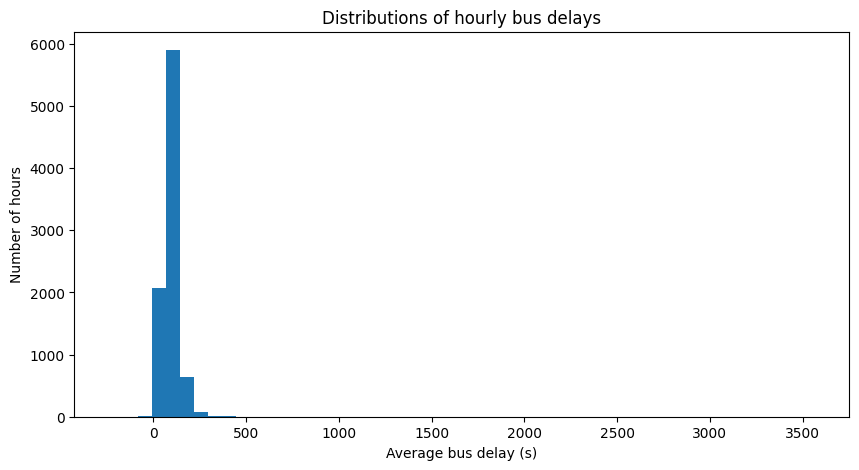

In [18]:
# Delay distribution

plt.figure(figsize = (10, 5))

plt.hist(
    data["average_delay"],
    bins = 50
)

plt.xlabel("Average bus delay (s)")
plt.ylabel("Number of hours")
plt.title("Distributions of hourly bus delays")

plt.show()

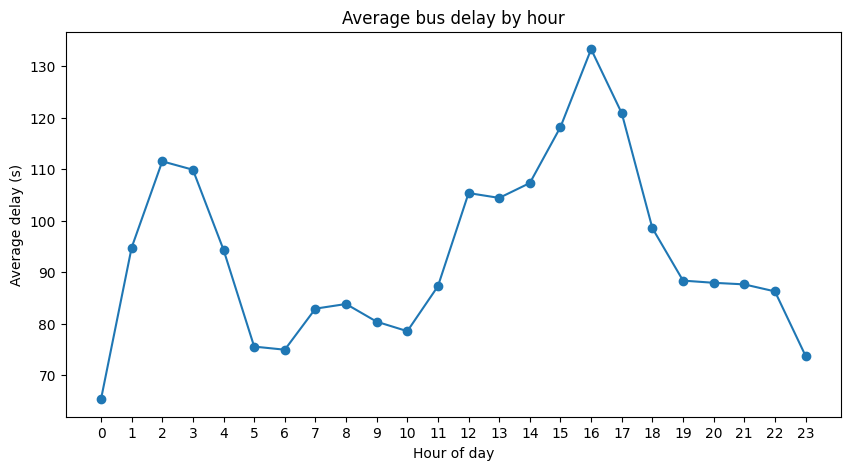

In [19]:
# Average delay by hour

hourly_delay = (
    data.groupby("hour")["average_delay"].mean()
)

plt.figure(figsize = (10, 5))

plt.plot(
    hourly_delay.index,
    hourly_delay.values,
    marker = "o"
)

plt.xlabel("Hour of day")
plt.ylabel("Average delay (s)")
plt.title("Average bus delay by hour")

plt.xticks(range(24))

plt.show()

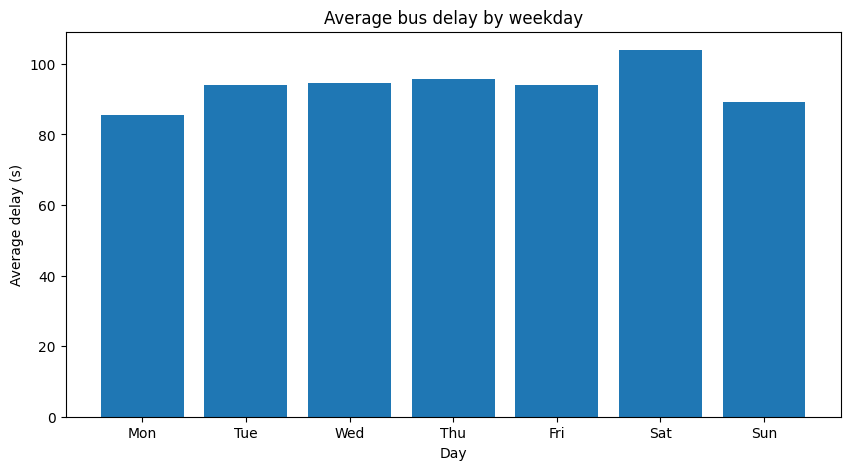

In [20]:
# Average delay by weekday

weekday_delay = (
    data.groupby("weekday")["average_delay"].mean()
)

weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.figure(figsize = (10, 5))

plt.bar(
    weekday_names,
    weekday_delay.values
)

plt.xlabel("Day")
plt.ylabel("Average delay (s)")
plt.title("Average bus delay by weekday")

plt.show()

### 2.3.1. Weather distributions

In [21]:
data[
    [
        "temperature",
        "precipitation",
        "wind_speed",
        "wind_gust"
    ]
].describe()

,temperature,precipitation,wind_speed,wind_gust
count,8726.000000,8725.000000,8728.000000,8728.000000
mean,8.338586,0.061880,3.150882,5.633169
std,8.333789,0.366158,1.617031,2.951114
min,-17.200000,0.000000,0.000000,0.000000
25%,1.700000,0.000000,2.000000,3.500000
50%,7.900000,0.000000,2.900000,5.100000
75%,15.300000,0.000000,4.100000,7.400000
max,27.900000,11.900000,11.200000,21.100000


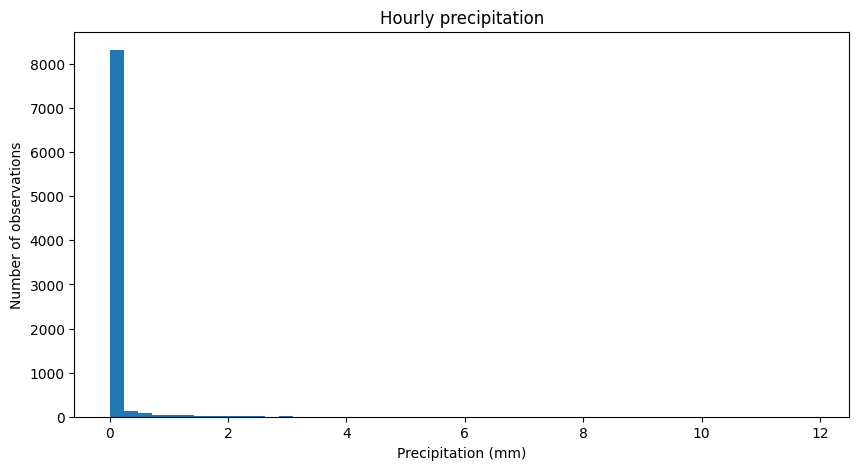

In [22]:
plt.figure(figsize = (10, 5))

plt.hist(
    data["precipitation"].dropna(),
    bins = 50
)

plt.xlabel("Precipitation (mm)")
plt.ylabel("Number of observations")
plt.title("Hourly precipitation")

plt.show()

### 2.3.2. Correlations

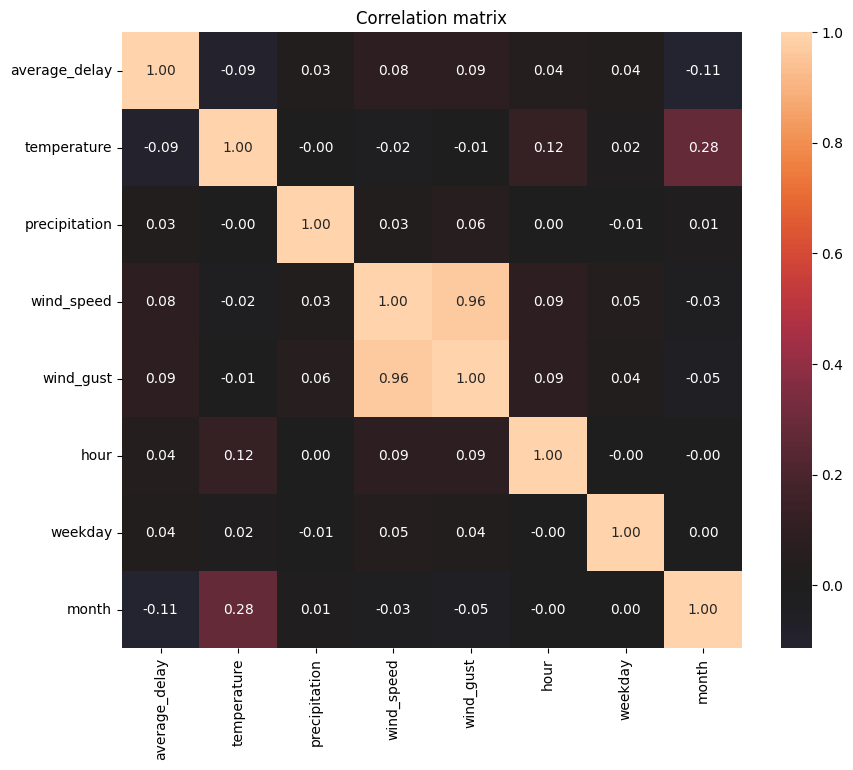

In [23]:
correlation_columns = [
    "average_delay",
    "temperature",
    "precipitation",
    "wind_speed",
    "wind_gust",
    "hour",
    "weekday",
    "month"
]

corr = data[correlation_columns].corr()

plt.figure(figsize = (10, 8))

sns.heatmap(
    corr,
    annot = True,
    fmt = ".2f",
    center = 0
)

plt.title("Correlation matrix")

plt.show()

### 2.3.3 Precipitation vs. delay

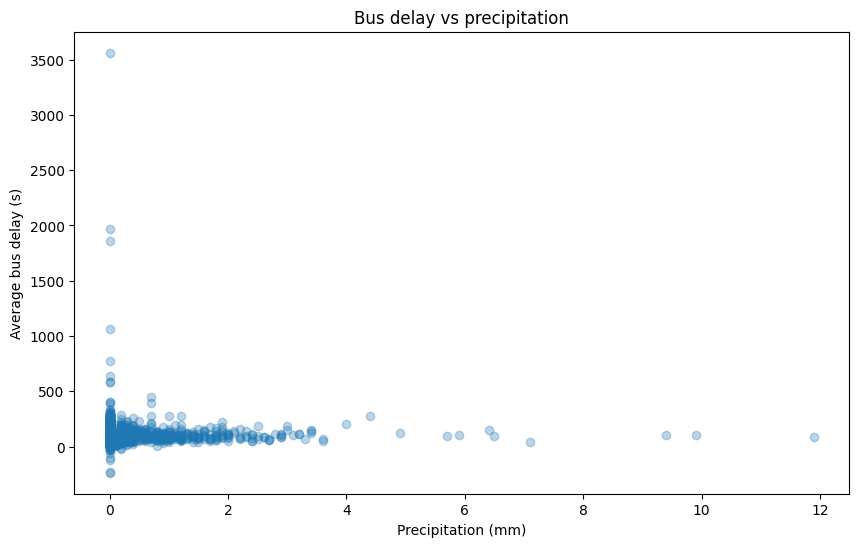

In [24]:
plt.figure(figsize = (10, 6))

plt.scatter(
    data["precipitation"],
    data["average_delay"],
    alpha = 0.3
)

plt.xlabel("Precipitation (mm)")
plt.ylabel("Average bus delay (s)")
plt.title("Bus delay vs precipitation")

plt.show()

In [25]:
data["rain_category"] = pd.cut(
    data["precipitation"],
    bins = [
        -0.001,
        0,
        0.5,
        2,
        np.inf
    ],
    labels = [
        "No rain",
        "Light rain",
        "Moderate rain",
        "Heavy rain"
    ]
)

rain_delay = (
    data.groupby(
        "rain_category",
        observed = False
    )["average_delay"].mean()
)

display(rain_delay)

,average_delay
rain_category,
No rain,93.365868
Light rain,95.993801
Moderate rain,104.130112
Heavy rain,107.496983


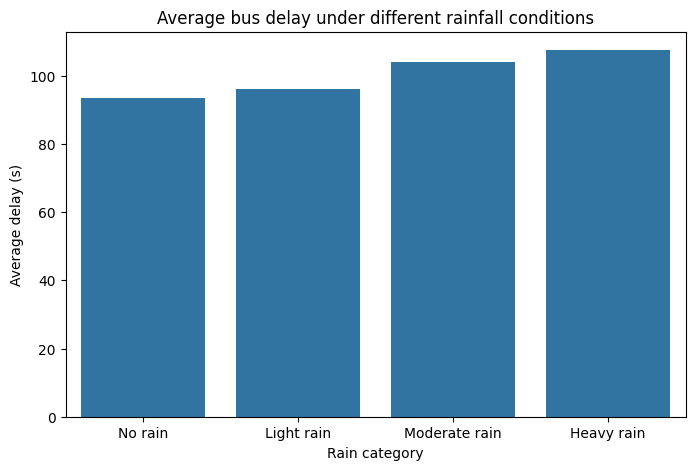

In [26]:
rain_delay_df = (
    data.groupby(
        "rain_category",
        observed=False
    )["average_delay"]
    .mean()
    .reset_index()
)

rain_delay_df.columns = [
    "Rain category",
    "Average delay (s)"
]

plt.figure(figsize=(8, 5))

sns.barplot(
    data=rain_delay_df,
    x="Rain category",
    y="Average delay (s)"
)

plt.xlabel("Rain category")
plt.ylabel("Average delay (s)")
plt.title("Average bus delay under different rainfall conditions")

plt.show()


## 2.4. Define prediction problem

In [27]:
# Model A: Time only

time_features = [
    "hour",
    "weekday",
    "month",
    "is_weekend",
    "is_rush_hour",
    "hour_sin",
    "hour_cos",
    "weekday_sin",
    "weekday_cos"
]

In [28]:
# Model B: Time + weather

weather_model_features = [
    "temperature",
    "precipitation",
    "wind_speed",
    "wind_gust",
    "temperature_lag1",
    "precipitation_lag1",
    "wind_speed_lag1",
    "wind_gust_lag1",
    "temperature_lag2",
    "precipitation_lag2",
    "wind_speed_lag2",
    "wind_gust_lag2",
    "precipitation_3h"
]

all_features = (
    time_features + weather_model_features
)

### 2.4.1. Remove rows affected by lagging

In [29]:
model_data = data.dropna(
    subset = all_features + ["average_delay"]
).copy()

print("Rows available for modelling:", len(model_data))

Rows available for modelling: 8717


# 3. Model selection, training, and evaluation

## 3.1. Chronological train/test split

In [30]:
split_date = (
    model_data["date"].quantile(0.75)
)

train = model_data[
    model_data["date"] <= split_date
].copy()

test = model_data[
    model_data["date"] > split_date
].copy()

print("Training period:")
print(train["date"].min(), "-->", train["date"].max())

print("\nTesting period:")
print(test["date"].min(), "-->", test["date"].max())

print("\nTraining observations:", len(train))
print("Testing observations:", len(test))

Training period:
2024-01-01 00:00:00 --> 2024-10-01 00:00:00

Testing period:
2024-10-02 00:00:00 --> 2024-12-31 00:00:00

Training observations: 6544
Testing observations: 2173


## 3.2. Prepare 𝑋 and 𝑦

In [31]:
X_train_time = train[time_features]
X_test_time = test[time_features]

X_train_weather = train[all_features]
X_test_weather = test[all_features]

y_train = train["average_delay"]
y_test = test["average_delay"]

## 3.3. Evaluation function

In [32]:
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name):

  model.fit(X_train, y_train)
  predictions = model.predict(X_test)

  mae = mean_absolute_error(y_test, predictions)
  rmse = np.sqrt(mean_squared_error(y_test, predictions))
  r2 = r2_score(y_test, predictions)

  return {
      "Model": model_name,
      "MAE (s)": mae,
      "RMSE (s)": rmse,
      "R2": r2
  }, predictions

## 3.4. Ridge regression


In [33]:
results = []
predictions = {}

In [34]:
# Time only

ridge_time = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy = "median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        Ridge(alpha = 1.0)
    )
])

result, pred = evaluate_model(
    ridge_time,
    X_train_time,
    X_test_time,
    y_train,
    y_test,
    "Ridge - Time only"
)

results.append(result)
predictions["Ridge - Time only"] = pred

In [35]:
# Time + weather

ridge_weather = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy = "median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        Ridge(alpha = 1.0)
    )
])

result, pred = evaluate_model(
    ridge_weather,
    X_train_weather,
    X_test_weather,
    y_train,
    y_test,
    "Ridge - Time + weather"
)

results.append(result)
predictions["Ridge - Time + weather"] = pred

## 3.5. Random Forest

In [36]:
# Time only

rf_time = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy = "median")
    ),
    (
        "model",
        RandomForestRegressor(
            n_estimators = 200,
            max_depth = 15,
            min_samples_leaf = 5,
            random_state = RANDOM_STATE,
            n_jobs = -1
        )
    )
])

result, pred = evaluate_model(
    rf_time,
    X_train_time,
    X_test_time,
    y_train,
    y_test,
    "Random Forest - Time only"
)

results.append(result)
predictions["Random Forest - Time only"] = pred

In [37]:
# Weather + time

rf_weather = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy = "median")
    ),
    (
        "model",
        RandomForestRegressor(
            n_estimators = 200,
            max_depth = 15,
            min_samples_leaf = 5,
            random_state = RANDOM_STATE,
            n_jobs = -1
        )
    )
])

result, pred = evaluate_model(
    rf_weather,
    X_train_weather,
    X_test_weather,
    y_train,
    y_test,
    "Random Forest - Time + weather"
)

results.append(result)
predictions["Random Forest - Time + weather"] = pred

## 3.6 Gradient boosting

In [38]:
# Time only

gb_time = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy = "median")
    ),
    (
        "model",
        HistGradientBoostingRegressor(
            max_iter = 200,
            learning_rate = 0.05,
            max_leaf_nodes = 15,
            l2_regularization = 1.0,
            random_state = RANDOM_STATE
        )
    )
])

result, pred = evaluate_model(
    gb_time,
    X_train_time,
    X_test_time,
    y_train,
    y_test,
    "Gradient Boosting - Time only"
)

results.append(result)
predictions["Gradient Boosting - Time only"] = pred

In [39]:
# Weather + time

gb_weather = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy = "median")
    ),
    (
        "model",
        HistGradientBoostingRegressor(
            max_iter = 200,
            learning_rate = 0.05,
            max_leaf_nodes = 15,
            l2_regularization = 1.0,
            random_state = RANDOM_STATE
        )
    )
])

result, pred = evaluate_model(
    gb_weather,
    X_train_weather,
    X_test_weather,
    y_train,
    y_test,
    "Gradient Boosting - Time + weather"
)

results.append(result)
predictions["Gradient Boosting - Time + weather"] = pred

## 3.7. Compare the models

In [40]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "MAE (s)"
)

display(results_df)

,Model,MAE (s),RMSE (s),R2
2,Random Forest - Time only,22.952265,65.248891,0.117488
3,Random Forest - Time + weather,23.833508,65.814975,0.102109
4,Gradient Boosting - Time only,24.099772,66.252951,0.090119
5,Gradient Boosting - Time + weather,25.311632,67.300012,0.061132
1,Ridge - Time + weather,31.097803,71.820640,-0.069234
0,Ridge - Time only,31.452638,72.102101,-0.077631


<function matplotlib.pyplot.show(close=None, block=None)>

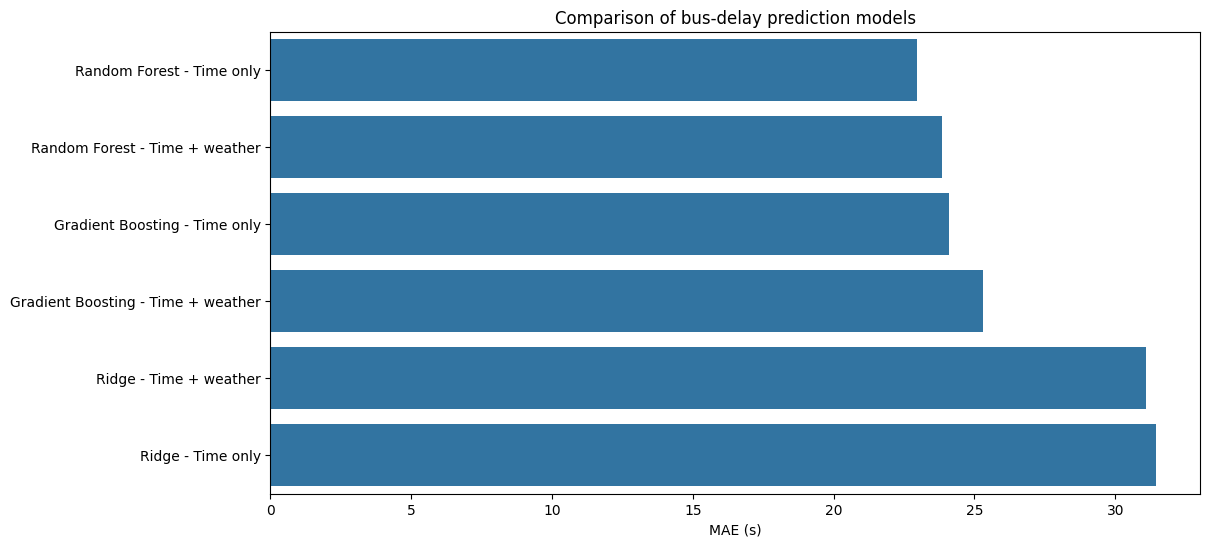

In [41]:
plt.figure(figsize = (12, 6))

sns.barplot(
    data = results_df,
    x = "MAE (s)",
    y = "Model"
)

plt.xlabel("MAE (s)")
plt.ylabel("")
plt.title("Comparison of bus-delay prediction models")

plt.show

## 3.8 Quantify the value of weather

Interpretation:

*   Positive improvement → weather helped
*   Negative improvement → weather made the model worse
*   Near zero → weather adds little predictive information



In [42]:
weather_comparison = []

for model_name in ["Ridge", "Random Forest", "Gradient Boosting"]:
  time_row = results_df[
      results_df["Model"] == f"{model_name} - Time only"
  ]

  weather_row = results_df[
      results_df["Model"] == f"{model_name} - Time + weather"
  ]

  if len(time_row) == 1 and len(weather_row) == 1:
    time_mae = time_row["MAE (s)"].iloc[0]
    weather_mae = weather_row["MAE (s)"].iloc[0]

    improvement = (time_mae - weather_mae)
    percentage = (improvement / time_mae * 100)

    weather_comparison.append({
        "Model": model_name,
        "Time-only MAE": time_mae,
        "Time + weather MAE": weather_mae,
        "Improvement (s)": improvement,
        "Improvement (%)": percentage
    })

weather_comparison = pd.DataFrame(weather_comparison)

display(weather_comparison)

,Model,Time-only MAE,Time + weather MAE,Improvement (s),Improvement (%)
0,Ridge,31.452638,31.097803,0.354835,1.128156
1,Random Forest,22.952265,23.833508,-0.881243,-3.839458
2,Gradient Boosting,24.099772,25.311632,-1.211861,-5.028515


# 3.9. Investigate the best model

In [43]:
best_model_name = (
    results_df.sort_values("MAE (s)").iloc[0]["Model"]
)

print("Best model:", best_model_name)

Best model: Random Forest - Time only


In [44]:
best_predictions = predictions[best_model_name]

In [45]:
diagnostics = test[
    [
        "date",
        "hour",
        "weekday",
        "month",
        "average_delay",
        "temperature",
        "precipitation",
        "wind_speed",
        "wind_gust"
    ]
].copy()

diagnostics["prediction"] = (best_predictions)

diagnostics["error"] = (
    diagnostics["average_delay"] - diagnostics["prediction"]
)

diagnostics["absolute_error"] = (diagnostics["error"].abs())

display(diagnostics.head())

,date,hour,weekday,month,average_delay,temperature,precipitation,wind_speed,wind_gust,prediction,error,absolute_error
6555,2024-10-02,0,2,10,35.521815,6.5,0.0,3.0,4.6,44.204378,-8.682563,8.682563
6556,2024-10-02,1,2,10,76.492823,6.8,0.0,2.6,4.4,77.946400,-1.453577,1.453577
6557,2024-10-02,2,2,10,95.029627,6.8,0.0,2.5,4.2,95.053827,-0.024199,0.024199
6558,2024-10-02,3,2,10,107.363014,6.9,0.0,2.5,4.9,91.162636,16.200378,16.200378
6559,2024-10-02,4,2,10,81.812388,7.5,0.0,2.5,4.9,94.144664,-12.332275,12.332275


### 3.9.1. Actual vs. predicted

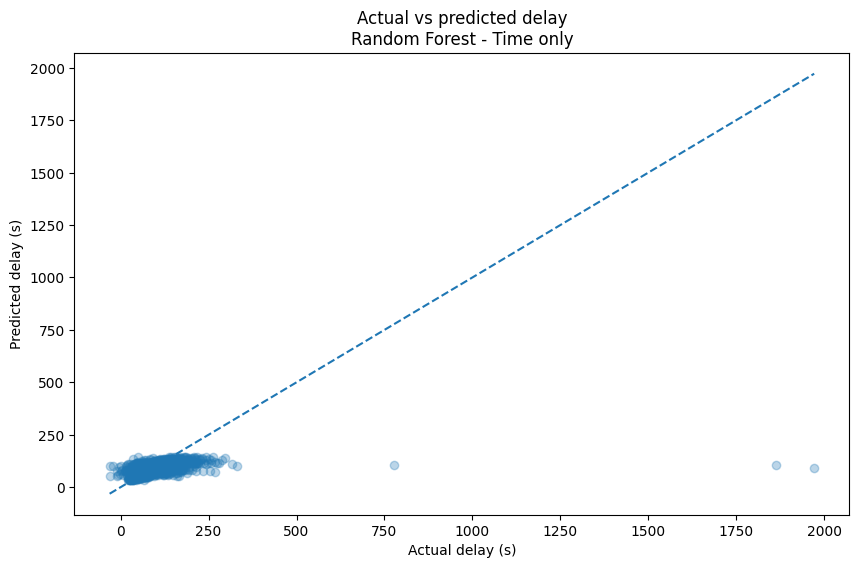

In [46]:
plt.figure(figsize = (10, 6))

plt.scatter(
    diagnostics["average_delay"],
    diagnostics["prediction"],
    alpha = 0.3
)

min_value = min(
    diagnostics["average_delay"].min(),
    diagnostics["prediction"].min()
)

max_value = max(
    diagnostics["average_delay"].max(),
    diagnostics["prediction"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle = "--"
)

plt.xlabel("Actual delay (s)")
plt.ylabel("Predicted delay (s)")
plt.title(f"Actual vs predicted delay\n{best_model_name}")

plt.show()

### 3.9.2. Diagnostics: performance by hour

In [47]:
hour_performance = (
    diagnostics.groupby("hour").apply(
        lambda x: pd.Series({
            "MAE": mean_absolute_error(
                x["average_delay"],
                x["prediction"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    x["average_delay"],
                    x["prediction"]
                )
            ),
            "n": len(x)
        }),
        include_groups = False
    ).reset_index()
)

display(hour_performance)

,hour,MAE,RMSE,n
0,0,10.384205,13.267378,91.0
1,1,17.664112,23.484662,90.0
2,2,28.093273,76.077741,90.0
3,3,40.772653,186.747183,90.0
4,4,35.723340,199.224660,90.0
5,5,12.568039,26.753629,90.0
6,6,18.769064,25.623739,90.0
7,7,24.254044,36.351439,90.0
8,8,28.744207,47.481513,90.0
9,9,19.139311,28.588385,90.0


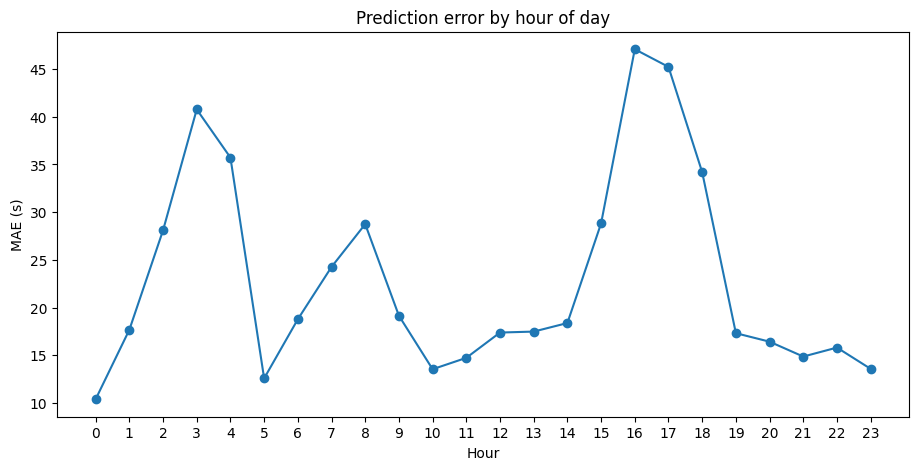

In [48]:
plt.figure(figsize = (11, 5))

plt.plot(
    hour_performance["hour"],
    hour_performance["MAE"],
    marker = "o"
)

plt.xlabel("Hour")
plt.ylabel("MAE (s)")
plt.title("Prediction error by hour of day")

plt.xticks(range(24))

plt.show()

### 3.9.3. Diagnostics: performance by month

In [49]:
month_performance = (
    diagnostics
    .groupby("month")
    .apply(
        lambda x: pd.Series({
            "MAE": mean_absolute_error(
                x["average_delay"],
                x["prediction"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    x["average_delay"],
                    x["prediction"]
                )
            ),
            "n": len(x)
        }),
        include_groups=False
    )
    .reset_index()
)

display(month_performance)

,month,MAE,RMSE,n
0,10,20.900040,101.674671,720.0
1,11,23.322837,36.853739,709.0
2,12,24.585151,33.705607,744.0


### 3.9.4. Diagnostics: performance under different rainfall

In [50]:
diagnostics["rain_category"] = pd.cut(
    diagnostics["precipitation"],
    bins = [
        -0.001,
        0,
        0.5,
        2,
        np.inf
    ],
    labels = [
        "No rain",
        "Light rain",
        "Moderate rain",
        "Heavy rain"
    ]
)

rain_performance = (
    diagnostics
    .groupby(
        "rain_category",
        observed=False
    )
    .apply(
        lambda x: pd.Series({
            "MAE": mean_absolute_error(
                x["average_delay"],
                x["prediction"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    x["average_delay"],
                    x["prediction"]
                )
            ),
            "n": len(x)
        }),
        include_groups=False
    )
    .reset_index()
)

display(rain_performance)

,rain_category,MAE,RMSE,n
0,No rain,22.922463,67.495485,1983.0
1,Light rain,20.026558,29.405936,124.0
2,Moderate rain,27.285451,35.787448,52.0
3,Heavy rain,36.992276,55.876939,14.0


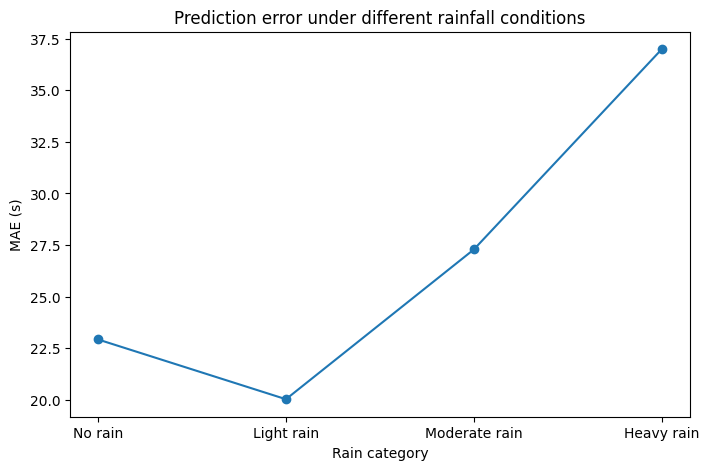

In [51]:
plt.figure(figsize=(8, 5))

plt.plot(
    rain_performance["rain_category"],
    rain_performance["MAE"],
    marker="o"
)

plt.xlabel("Rain category")
plt.ylabel("MAE (s)")
plt.title("Prediction error under different rainfall conditions")

plt.show()


### 3.9.5. Feature importance

In [52]:
rf_weather.fit(X_train_weather, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 RandomForestRegressor(max_depth=15, min_samples_leaf=5,
                                       n_estimators=200, n_jobs=-1,
                                       random_state=42))])

In [53]:
rf_model = rf_weather.named_steps["model"]

In [54]:
importance = pd.DataFrame({
    "Feature": all_features,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending = False
)

display(importance)

,Feature,Importance
2,month,0.257895
9,temperature,0.089416
17,temperature_lag2,0.084301
5,hour_sin,0.080242
0,hour,0.067573
13,temperature_lag1,0.056482
7,weekday_sin,0.046726
6,hour_cos,0.045806
19,wind_speed_lag2,0.035438
12,wind_gust,0.033297


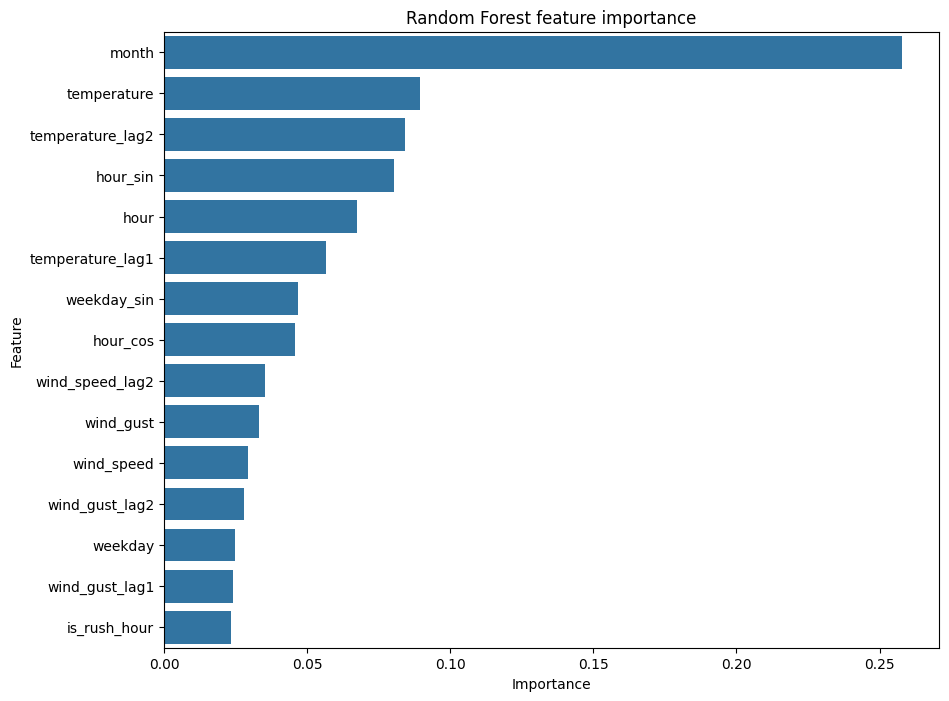

In [55]:
plt.figure(figsize = (10, 8))

sns.barplot(
    data = importance.head(15),
    x = "Importance",
    y = "Feature"
)

plt.title("Random Forest feature importance")

plt.show()

### 3.9.6. Missing-weather robustness experiment

In [56]:
def evaluate_missing_weather(model, X_test, y_test, weather_columns, missing_rate):
  X_missing = X_test.copy()

  rng = np.random.default_rng(RANDOM_STATE)

  for col in weather_columns:
    mask = (rng.random(len(X_missing)) < missing_rate)

    X_missing.loc[
        mask,
        col
    ] = np.nan

    predictions = model.predict(X_missing)
    mae = mean_absolute_error(y_test, predictions)

  return mae

In [57]:
missing_results = []

for rate in [0.00, 0.05, 0.10, 0.20, 0.30, 0.50, 0.70, 0.80, 0.85, 0.90, 0.95]:
  mae = evaluate_missing_weather(
      rf_weather,
      X_test_weather,
      y_test,
      weather_model_features,
      rate
  )

  missing_results.append({
      "Missing weather": rate * 100,
      "MAE": mae
  })

missing_results = pd.DataFrame(missing_results)

display(missing_results)

,Missing weather,MAE
0,0.0,23.833508
1,5.0,23.887366
2,10.0,23.926193
3,20.0,24.062719
4,30.0,24.306839
5,50.0,24.420474
6,70.0,24.194257
7,80.0,24.191187
8,85.0,24.248432
9,90.0,24.236545


<function matplotlib.pyplot.show(close=None, block=None)>

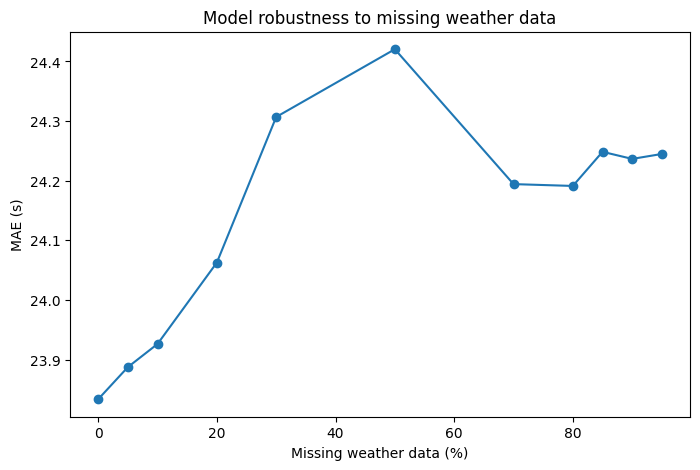

In [58]:
plt.figure(figsize = (8, 5))

plt.plot(
    missing_results["Missing weather"],
    missing_results["MAE"],
    marker = "o"
)

plt.xlabel("Missing weather data (%)")
plt.ylabel("MAE (s)")
plt.title("Model robustness to missing weather data")

plt.show

### 3.9.7. Actual vs. predicted bus delays

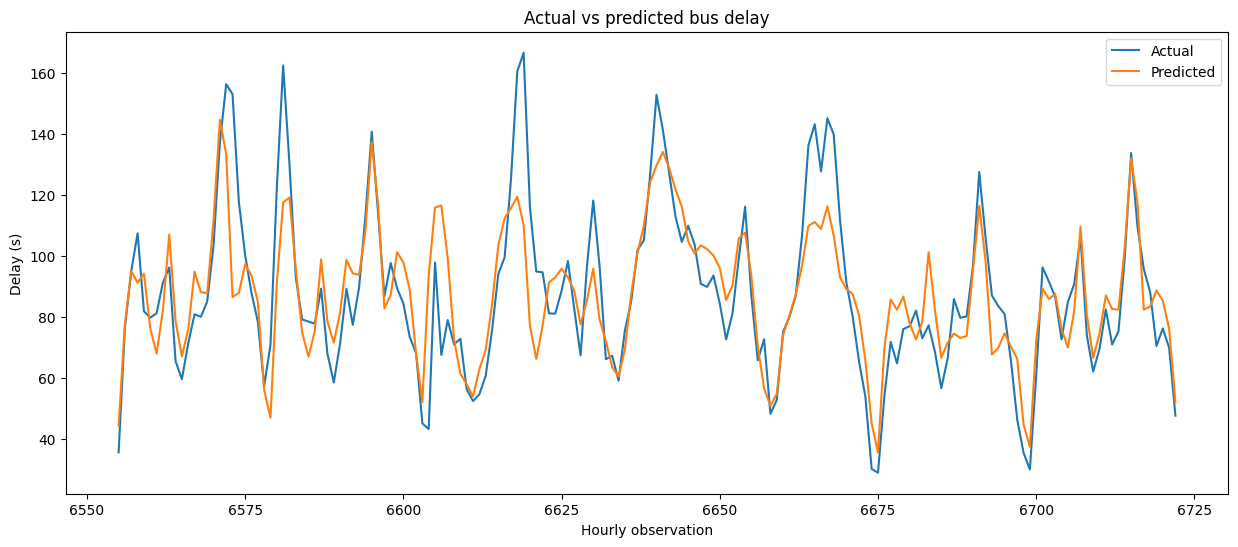

In [59]:
plot_data = diagnostics.iloc[:168].copy()

plt.figure(figsize = (15, 6))

plt.plot(
    plot_data.index,
    plot_data["average_delay"],
    label = "Actual"
)

plt.plot(
    plot_data.index,
    plot_data["prediction"],
    label = "Predicted"
)

plt.xlabel("Hourly observation")
plt.ylabel("Delay (s)")
plt.title("Actual vs predicted bus delay")

plt.legend()
plt.show()